<a href="https://colab.research.google.com/github/akashqchem/Graph_neural_networks/blob/main/Predicting_molecular_solubility_using_GNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Installing the package

In [1]:
!pip install dmol-book

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of sphinx-book-theme to determine which version is compatible with other requirements. This could take a while.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 24.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 60.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 49.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 58.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 46.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 72.2 MB/s  0:00:

#Importing all the necessary libraries

In [6]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import rdkit, rdkit.Chem, rdkit.Chem.rdDepictor, rdkit.Chem.Draw
import networkx as nx
import dmol

#Loading and preparing the solubility dataset

In [7]:
soldata = pd.read_csv(
    "https://github.com/whitead/dmol-book/raw/main/data/curated-solubility-dataset.csv"
)
# filter any whose smiles don't read in correctly (this changes depending on rdkit version, so we check here)
N = len(soldata)
soldata = soldata[soldata.SMILES.apply(lambda x: rdkit.Chem.MolFromSmiles(x) is not None)].reset_index(drop=True)
print(f"Dropped {N - len(soldata)} rows with invalid SMILES")

np.random.seed(0)
my_elements = {6: "C", 8: "O", 1: "H"}

Dropped 2 rows with invalid SMILES


#Converting SMILES into molecular graphs

In [8]:
def smiles2graph(sml):
    """Argument for the RD2NX function should be a valid SMILES sequence
    returns: the graph
    """
    m = rdkit.Chem.MolFromSmiles(sml)
    m = rdkit.Chem.AddHs(m)
    order_string = {
        rdkit.Chem.rdchem.BondType.SINGLE: 1,
        rdkit.Chem.rdchem.BondType.DOUBLE: 2,
        rdkit.Chem.rdchem.BondType.TRIPLE: 3,
        rdkit.Chem.rdchem.BondType.AROMATIC: 4,
    }
    N = len(list(m.GetAtoms()))
    nodes = np.zeros((N, len(my_elements)))
    lookup = list(my_elements.keys())
    for i in m.GetAtoms():
        nodes[i.GetIdx(), lookup.index(i.GetAtomicNum())] = 1

    adj = np.zeros((N, N, 5))
    for j in m.GetBonds():
        u = min(j.GetBeginAtomIdx(), j.GetEndAtomIdx())
        v = max(j.GetBeginAtomIdx(), j.GetEndAtomIdx())
        order = j.GetBondType()
        if order in order_string:
            order = order_string[order]
        else:
            raise Warning("Ignoring bond order" + order)
        adj[u, v, order] = 1
        adj[v, u, order] = 1
    return nodes, adj

#Testing molecular graph representation

In [9]:
nodes, adj = smiles2graph("CO")
nodes

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 0., 1.]])

#Preparing the adjacency matrix

In [10]:
nodes, adj = smiles2graph("CO")
adj_mat = np.sum(adj, axis=-1) + np.eye(adj.shape[0])
adj_mat

array([[1., 1., 1., 1., 1., 0.],
       [1., 1., 0., 0., 0., 1.],
       [1., 0., 1., 0., 0., 0.],
       [1., 0., 0., 1., 0., 0.],
       [1., 0., 0., 0., 1., 0.],
       [0., 1., 0., 0., 0., 1.]])

#Building the graph convolution layer

In [11]:
class GCNLayer(nn.Module):
    """Implementation of GCN as layer"""

    def __init__(self, in_features, out_features, activation=None):
        super(GCNLayer, self).__init__()
        self.w = nn.Parameter(torch.empty(in_features, out_features))
        nn.init.xavier_uniform_(self.w)
        self.activation = activation

    def forward(self, nodes, adj):
        degree = torch.sum(adj, dim=-1)
        new_nodes = torch.einsum("bi,bij,bjk,kl->bil", 1 / degree, adj, nodes, self.w)
        if self.activation is not None:
            new_nodes = self.activation(new_nodes)
        return new_nodes, adj

#Building the graph readout layer

In [12]:
class GRLayer(nn.Module):
    """A GNN layer that computes average over all node features"""

    def __init__(self):
        super(GRLayer, self).__init__()

    def forward(self, nodes, adj):
        reduction = torch.mean(nodes, dim=1)
        return reduction

#Building the GNN model

In [13]:
class SolubilityModel(nn.Module):
    def __init__(self, node_features=100):
        super(SolubilityModel, self).__init__()
        self.gcn1 = GCNLayer(node_features, node_features, activation=F.relu)
        self.gcn2 = GCNLayer(node_features, node_features, activation=F.relu)
        self.gcn3 = GCNLayer(node_features, node_features, activation=F.relu)
        self.gcn4 = GCNLayer(node_features, node_features, activation=F.relu)
        self.gr = GRLayer()
        self.fc1 = nn.Linear(node_features, 16)
        self.fc2 = nn.Linear(16, 1)

    def forward(self, nodes, adj):
        x, adj = self.gcn1(nodes, adj)
        x, adj = self.gcn2(x, adj)
        x, adj = self.gcn3(x, adj)
        x, adj = self.gcn4(x, adj)
        x = self.gr(x, adj)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = SolubilityModel()

#Preparing molecular inputs

In [14]:
def gen_smiles2graph(sml):
    """Argument for the RD2NX function should be a valid SMILES sequence
    returns: the graph
    """
    m = rdkit.Chem.MolFromSmiles(sml)
    m = rdkit.Chem.AddHs(m)
    order_string = {
        rdkit.Chem.rdchem.BondType.SINGLE: 1,
        rdkit.Chem.rdchem.BondType.DOUBLE: 2,
        rdkit.Chem.rdchem.BondType.TRIPLE: 3,
        rdkit.Chem.rdchem.BondType.AROMATIC: 4,
    }
    N = len(list(m.GetAtoms()))
    nodes = np.zeros((N, 100))
    for i in m.GetAtoms():
        nodes[i.GetIdx(), i.GetAtomicNum()] = 1

    adj = np.zeros((N, N))
    for j in m.GetBonds():
        u = min(j.GetBeginAtomIdx(), j.GetEndAtomIdx())
        v = max(j.GetBeginAtomIdx(), j.GetEndAtomIdx())
        order = j.GetBondType()
        if order in order_string:
            order = order_string[order]
        else:
            raise Warning("Ignoring bond order" + order)
        adj[u, v] = 1
        adj[v, u] = 1
    adj += np.eye(N)
    return nodes, adj

In [15]:
nodes, adj = gen_smiles2graph("CO")
nodes_t = torch.from_numpy(nodes[np.newaxis, ...]).float()
adj_mat_t = torch.from_numpy(adj[np.newaxis, ...]).float()
model(nodes_t, adj_mat_t)

tensor([[-0.2272]], grad_fn=<AddmmBackward0>)

#Creating training, validation, and test datasets

In [16]:
from torch.utils.data import Dataset, DataLoader

class SolubilityDataset(Dataset):
    def __init__(self, data, start_idx=0, end_idx=None):
        self.data = data
        self.start_idx = start_idx
        self.end_idx = end_idx if end_idx is not None else len(data)

    def __len__(self):
        return self.end_idx - self.start_idx

    def __getitem__(self, idx):
        idx = idx + self.start_idx
        nodes, adj = gen_smiles2graph(self.data.SMILES[idx])
        sol = self.data.Solubility[idx]
        # this time we do not batch - it will be done by dataloader
        nodes_t = torch.from_numpy(nodes).float()
        adj_t = torch.from_numpy(adj).float()
        return (nodes_t, adj_t), torch.tensor(sol, dtype=torch.float32)

In [17]:
test_data = SolubilityDataset(soldata, 0, 200)
val_data = SolubilityDataset(soldata, 200, 400)
train_data = SolubilityDataset(soldata, 400)

#Training the GNN

In [18]:
train_loader = DataLoader(train_data, batch_size=1, shuffle=True)
val_loader = DataLoader(val_data, batch_size=1, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()

history = {"loss": [], "val_loss": []}
epochs = 10

for epoch in range(epochs):
    model.train()
    train_loss = 0
    for (nodes, adj), y in train_loader:
        optimizer.zero_grad()
        y_pred = model(nodes, adj)
        loss = criterion(y_pred.squeeze(), y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for (nodes, adj), y in val_loader:
            y_pred = model(nodes, adj)
            loss = criterion(y_pred.squeeze(), y)
            val_loss += loss.item()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)
    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

Epoch 1/10, Train Loss: 3.6320, Val Loss: 2.1547
Epoch 2/10, Train Loss: 3.0722, Val Loss: 2.0933
Epoch 3/10, Train Loss: 2.8320, Val Loss: 1.8295
Epoch 4/10, Train Loss: 2.6685, Val Loss: 1.8761
Epoch 5/10, Train Loss: 2.5071, Val Loss: 1.9867
Epoch 6/10, Train Loss: 2.4573, Val Loss: 1.8457
Epoch 7/10, Train Loss: 2.3401, Val Loss: 2.0834
Epoch 8/10, Train Loss: 2.2633, Val Loss: 1.8268
Epoch 9/10, Train Loss: 2.2001, Val Loss: 1.9473
Epoch 10/10, Train Loss: 2.1159, Val Loss: 1.5249


#Visualizing training performance

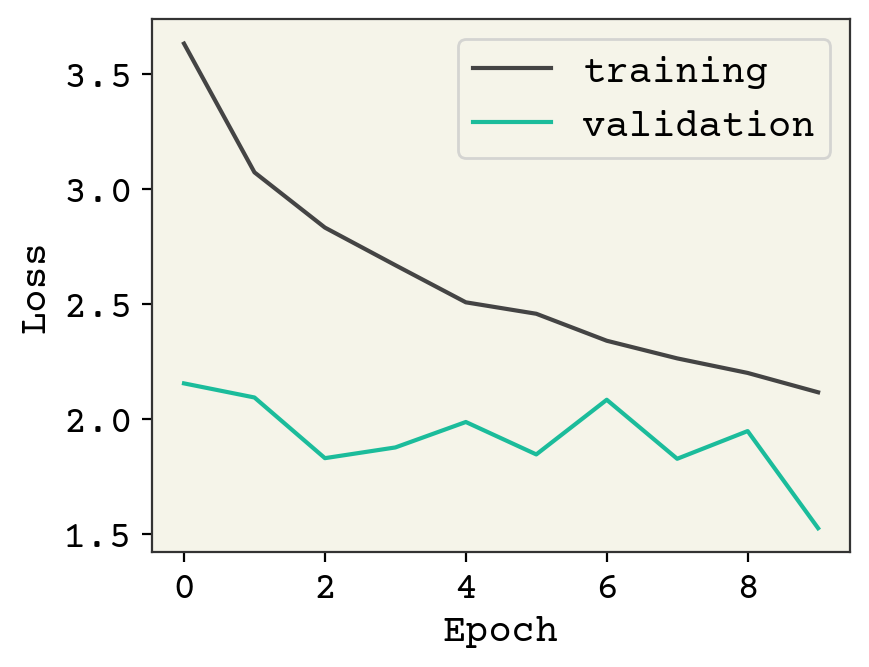

In [19]:
plt.plot(history["loss"], label="training")
plt.plot(history["val_loss"], label="validation")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

#Evaluating molecular solubility predictions

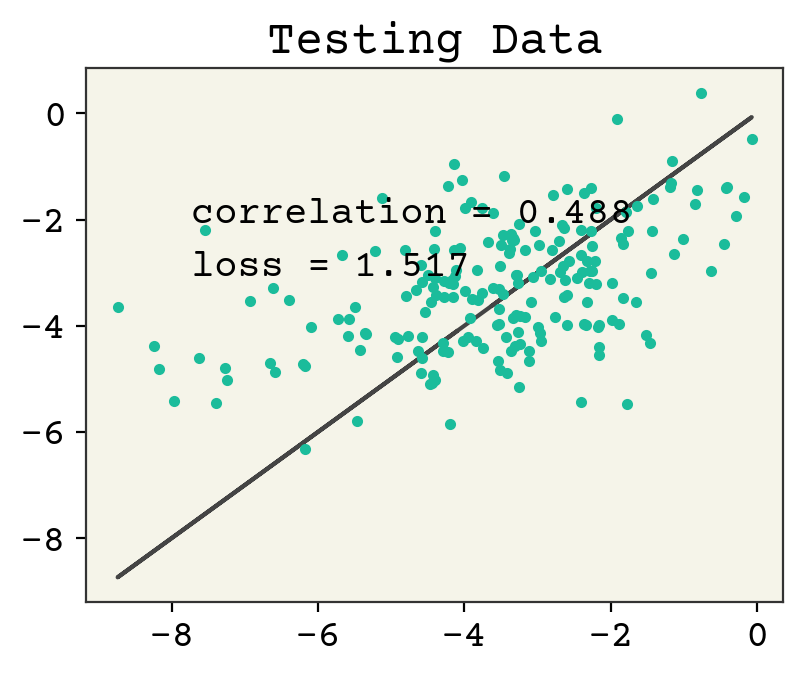

In [20]:
model.eval()
yhat = []
test_y = []
test_loader = DataLoader(test_data, batch_size=1, shuffle=False)
with torch.no_grad():
    for (nodes, adj), y in test_loader:
        pred = model(nodes, adj)
        yhat.append(pred.squeeze().item())
        test_y.append(y.item())

plt.figure()
plt.plot(test_y, test_y, "-")
plt.plot(test_y, yhat, ".")
plt.text(
    min(test_y) + 1,
    max(test_y) - 2,
    f"correlation = {np.corrcoef(test_y, yhat)[0,1]:.3f}",
)
plt.text(
    min(test_y) + 1,
    max(test_y) - 3,
    f"loss = {np.sqrt(np.mean((np.array(test_y) - np.array(yhat))**2)):.3f}",
)
plt.title("Testing Data")
plt.show()